# 01. Product KPIs and Funnels

This notebook measures the journey from visiting Venture to generating, saving, and sharing an outing.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

WORKSPACE = Path.cwd()
if WORKSPACE.name == "notebooks":
    WORKSPACE = WORKSPACE.parent

sys.path.insert(0, str(WORKSPACE / "src"))

from venture_ds import (
    load_exports,
    load_optional_export,
    safe_rate,
    wilson_interval,
    ordered_session_funnel,
    add_sample_warning,
)

exports = load_exports(WORKSPACE / "data" / "raw")
events = exports["events"]
sessions = exports["sessions"]
feedback = exports["feedback"]
inventory = exports["inventory"]

exports["_files"]

,dataset,path,found
0,events,C:\Users\ppmal\Documents\Projects\venture-prod...,True
1,sessions,C:\Users\ppmal\Documents\Projects\venture-prod...,True
2,feedback,C:\Users\ppmal\Documents\Projects\venture-prod...,True
3,inventory,C:\Users\ppmal\Documents\Projects\venture-prod...,True


In [2]:
if sessions.empty:
    print("No sessions export found.")
else:
    summary = {
        "visitors": sessions["visitor_id"].nunique(),
        "sessions": sessions["session_id"].nunique(),
        "page_views": sessions["page_view_count"].sum(),
        "average_session_depth": sessions["page_view_count"].mean(),
        "bounce_rate": sessions["bounced"].mean(),
        "outing_generation_sessions": sessions["generated_outing"].sum(),
        "share_sessions": sessions["shared_outing"].sum(),
    }
    display(pd.Series(summary))
    print(add_sample_warning(len(sessions), minimum=20))

visitors                       1.000000
sessions                       3.000000
page_views                    14.000000
average_session_depth          4.666667
bounce_rate                    0.333333
outing_generation_sessions     1.000000
share_sessions                 1.000000
dtype: float64

Directional only: sample size is 3, below the working minimum of 20.


DISCOVERY FUNNEL


,step,sessions,step_rate,step_rate_pct
0,Visited,2,0.666667,66.7
1,Viewed discovery,0,0.000000,0.0
2,Opened listing,0,0.000000,0.0



OUTING BUILDER FUNNEL


,step,sessions,step_rate,step_rate_pct
0,Opened builder,1,0.333333,33.3
1,Generated outing,1,1.000000,100.0
2,Viewed results,1,1.000000,100.0
3,Saved outing,1,1.000000,100.0
4,Shared outing,1,1.000000,100.0


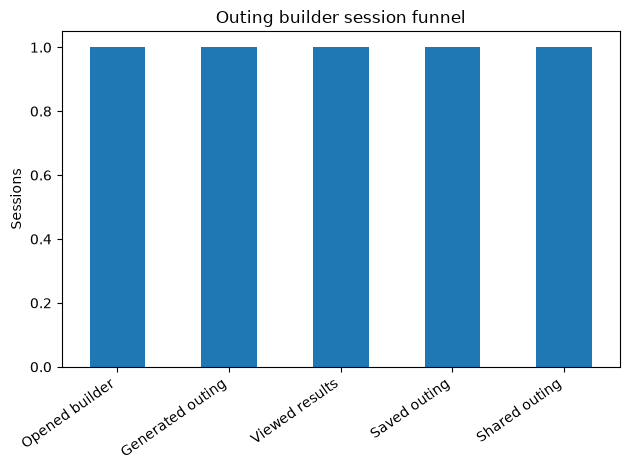

In [3]:
builder_funnel_steps = [
    ("Opened builder", {"outing_builder_opened"}),
    ("Generated outing", {"outing_generated"}),
    ("Viewed results", {"outing_result_viewed"}),
    ("Saved outing", {"outing_saved"}),
    ("Shared outing", {"outing_shared"}),
]

discovery_funnel_steps = [
    ("Visited", {"page_view"}),
    ("Viewed discovery", {"discovery_viewed"}),
    ("Opened listing", {"listing_detail_opened"}),
]

if not events.empty:
    print("DISCOVERY FUNNEL")

    discovery_funnel = ordered_session_funnel(
        events,
        discovery_funnel_steps,
    )

    discovery_funnel["step_rate_pct"] = (
        discovery_funnel["step_rate"] * 100
    ).round(1)

    display(discovery_funnel)

    print("\nOUTING BUILDER FUNNEL")

    builder_funnel = ordered_session_funnel(
        events,
        builder_funnel_steps,
    )

    builder_funnel["step_rate_pct"] = (
        builder_funnel["step_rate"] * 100
    ).round(1)

    display(builder_funnel)

    ax = builder_funnel.plot(
        x="step",
        y="sessions",
        kind="bar",
        legend=False,
        title="Outing builder session funnel",
    )

    ax.set_xlabel("")
    ax.set_ylabel("Sessions")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()

## Decision questions

- Where is the largest meaningful drop?
- Is the problem discovery, the builder, result quality, or post-result value?
- Does a low save rate reflect weak recommendations, a confusing interface, or simply insufficient inventory?